# Directional source time functions: forward demo

This notebook shows how source time function (STF) characteristics show up in full waveforms and spectra. It is forward modelling only, with no inversion.

1. **Formal GFs.** A very small full-space Salvus run with a flat-spectrum wavelet is turned into formal band-limited Green's functions. `Dataset.remove_stf` divides out the wavelet's moment rate, so the GFs only represent the path, band-limited by B.
2. **Single Brune.** The GFs for a known double couple are convolved with a causal Brune moment rate, $\dot M(t) = \omega_c^2\, t\, e^{-\omega_c t}$ with spectrum $1/(1 + i f/f_c)^2$. Varying $f_c$ shows its effect on spectra and waveforms compared with synthetic data.
3. **Two Brunes sharing one corner frequency $f_{c0}$.** The source is the linear sum of a symmetric and a directional Brune, $S = (1-w_2)\,S(f; f_{c0}) + w_2\,S(f; f_{c2}(\hat r))$:
   - the symmetric STF has corner $f_{c0}$ in every direction;
   - the directional STF has the **same** $f_{c0}$ perpendicular to the rupture, Doppler-shifted with direction, $f_{c2} = f_{c0} / (1 - (v_r/c)\cos\theta)$ from `spectra.apparent_fc`;
   - $w_2$, the moment fraction of the directional STF, is the same at every receiver.

Geometry: homogeneous ice in a full space. 50 three-component velocity receivers sit on a 35 m ring in the source's horizontal plane, at evenly spaced azimuths. Kernel: the `salvus_src_inv` env.

In [1]:
import glob
import os
import time
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import obspy
import pandas as pd

import unshake
from unshake import forward, misfit, mt, plot, spectra, stfs

%matplotlib inline
plt.rcParams['figure.dpi'] = 110

OUT = Path('stf_demo_out')                 # outputs (git-ignored)
SYNTH_DIR = OUT / 'salvus_gfs'             # Salvus synthetics (MSEED)
DS_PATH = OUT / 'stf_demo_dataset.pkl'     # formal-GF Dataset
PROJECT_PATH = '/Volumes/4tb_extssd/salvus_tmp_workspace/unshake_stf_demo'  # temporary: the driver deletes and recreates it!
OUT.mkdir(exist_ok=True)

## 1. Small Salvus run (cached)

Settings:
- **Medium:** homogeneous ice full-space (vp 3540, vs 1820, ρ 917), with high Q so that attenuation doesn't hide the STF.
- **Wavelet:** `FlatSpectrumWavelet(5, 10, 140, 150)` with a 0.04 s shift, mesh up to 150 Hz.
- **Full space:** `gen_body_waves_only=True`, so the boundaries absorb on all sides.

Driver conventions:
- coordinates are passed in metres / 1e6, because the driver multiplies by 1e6;
- in full space it moves receivers 10 m down, so we put the source at z = −10 m and the receivers at z = 0, which places the ring in the source plane;
- receiver names must not start with `D`, which would trigger the DAS projection.

The run is skipped when synthetics already exist in `SYNTH_DIR`.

In [2]:
# Geometry (metres, ENU):
vp, vs, rho = 3540.0, 1820.0, 917.0
Q_mu = 1000.0
src_xyz = np.array([0.0, 0.0, -10.0])
n_rec, radius = 50, 35.0
rec_az = np.arange(n_rec) * 360.0 / n_rec                     # degrees clockwise from north
rec_names = [f"R{i:02d}" for i in range(n_rec)]
rec_xyz = np.column_stack([radius * np.sin(np.radians(rec_az)), radius * np.cos(np.radians(rec_az)),
                           np.full(n_rec, src_xyz[2])])

# Simulation settings:
fs = 1000.0
band = (2.0, 20.0, 200.0, 210.0)                             # band filter B for GFs and data
max_frequency_in_hertz = 220.0                                # maximum frequency for Salvus GFs
end_time = 0.08 #0.16                                               # s (includes the 0.04 s wavelet shift)
domain_dict = {'x0': -50.0, 'x1': 50.0, 'y0': -50.0, 'y1': 50.0, 'z0': -40.0, 'z1': 40.0}
run_fwd = not glob.glob(str(SYNTH_DIR / '*.m'))
print('run_fwd =', run_fwd)

run_fwd = False


In [3]:
if run_fwd:
    import salvus.namespace as sn
    from unshake.salvus_fwd_driver import gen_synths_salvus

    wavelet = sn.simple_config.stf.FlatSpectrumWavelet(f0=band[0]/2, f1=band[0], f2=band[-1], f3=1.1*band[-1], time_shift_in_seconds=0.04)
    receivers_df = pd.DataFrame({'Name': rec_names, 'x_m': rec_xyz[:, 0] / 1e6, 'y_m': rec_xyz[:, 1] / 1e6,
                                 'z_m': np.zeros(n_rec)})      # driver puts full-space receivers at z = -10 m
    x = y = np.linspace(-200, 200, 41)
    z = np.linspace(-200, 200, 41)
    shape = (len(x), len(y), len(z))
    medium_model_dict = {'vp': np.full(shape, vp), 'vs': np.full(shape, vs), 'rho': np.full(shape, rho),
                         'qkappa': np.full(shape, 2 * Q_mu), 'qmu': np.full(shape, Q_mu), 'x': x, 'y': y, 'z': z}
    out_settings = {'output_fs_Hz': int(fs), 'gaussian_noise_dur_s': 0, 'snr_amp': 100.0,
                    'add_noise_to_signal': False, 'wfs_outdir': str(SYNTH_DIR)}
    tic = time.time()
    gen_synths_salvus(PROJECT_PATH, domain_dict, src_xyz / 1e6, receivers_df, medium_model_dict,
                      centre_freq_Hz=100.0,   # only the absorbing-boundary reference frequency here
                      output_waveforms_settings_dict=out_settings, gen_body_waves_only=True,
                      end_time_in_seconds=end_time, wavelet=wavelet, max_frequency_in_hertz=max_frequency_in_hertz,
                      elements_per_wavelength=2.0)
    print(f"Salvus run time: {time.time() - tic:.0f} s")
    # Save the wavelet's moment rate, so later runs don't need Salvus:
    t_rate, rate = wavelet.get_stf_rate()
    np.savez(OUT / 'wavelet_rate.npz', t=t_rate - wavelet.get_auto_start_time(), rate=rate)

## 2. Formal band-limited GF Dataset

Steps:
1. **Remove the wavelet.** Salvus applies the wavelet as the moment M(t), so we divide out its moment rate and apply B. The traces start at the simulation start time, which makes sample 0 the origin time.
2. **Reorder to NED:** [nn, ee, dd, ne, nd, ed] = [Myy, Mxx, Mzz, Mxy, −Myz, −Mxz].
3. **Rotate to Z/R/T:** P falls mostly on R, and S on T and Z.
4. **Window** to the first 0.1 s, where the deconvolved GFs are fully recorded.

In [4]:
mt_comps_salvus = ['Mxx', 'Myy', 'Mzz', 'Mxy', 'Mxz', 'Myz']
w = np.load(OUT / 'wavelet_rate.npz')
gf_enu = None
for j, Mc in enumerate(mt_comps_salvus):
    for k, ch in enumerate(['HHE', 'HHN', 'HHZ']):
        for i, name in enumerate(rec_names):
            tr = obspy.read(str(SYNTH_DIR / f"2000001_{name}_{ch}_{Mc}.m"))[0]
            if gf_enu is None:
                gf_enu = np.zeros((n_rec, 3, 6, tr.stats.npts))
            gf_enu[i, k, j] = tr.data[:gf_enu.shape[-1]]
dt = 1.0 / fs
gf_enu = forward.remove_stf(gf_enu, dt, (w['t'], w['rate']), band)

# NED source order and sign (Salvus x = east, y = north, z = up):
ned_idx, ned_sign = [1, 0, 2, 3, 5, 4], np.array([1., 1., 1., 1., -1., -1.])
gf_enu = gf_enu[:, :, ned_idx] * ned_sign[None, None, :, None]

# Rotate receiver components ENU -> Z, R, T:
phi = np.radians(rec_az)
comp_dirs = {'Z': np.tile([0., 0., 1.], (n_rec, 1)),
             'R': np.column_stack([np.sin(phi), np.cos(phi), np.zeros(n_rec)]),
             'T': np.column_stack([np.cos(phi), -np.sin(phi), np.zeros(n_rec)])}
labels, coords, chans, gfs = [], [], [], []
for c, d in comp_dirs.items():
    for i in range(n_rec):
        labels.append(f"{rec_names[i]}{c}")
        coords.append(rec_xyz[i])
        chans.append(d[i])
        gfs.append(np.einsum('k,kjt->jt', d[i], gf_enu[i]))
gf = np.array(gfs)

ds_gf = unshake.Dataset(
    data=np.zeros((gf.shape[0], gf.shape[-1])), gf={'mt': gf}, dt=dt,
    receivers=unshake.Receivers(labels=labels, coords=coords, channel_dirs=chans, phase='P', velocity=vp),
    source=unshake.Source(uid='stf_demo', coords=src_xyz), t0=0.0,
    meta={'gf': 'Salvus full space, homogeneous ice, FlatSpectrumWavelet(5, 10, 140, 150); '
                'moment-rate STF removed -> formal band-limited GF (velocity per unit moment rate impulse)',
          'gf_band': band, 'data_band': band, 'fmax_mesh_Hz': 150.0, 'Q_mu': Q_mu}).window(0.0, 0.1)
ds_gf.save(DS_PATH)
ds_gf.check_band()
print(ds_gf)

Note: GFs and data must be band-limited by the same filter B: gf_band=(2.0, 20.0, 200.0, 210.0), data_band=(2.0, 20.0, 200.0, 210.0)
Dataset(uid='stf_demo', n_rec=150, n_t=100, dt=0.001, gf=[mt(150, 6, 100)])


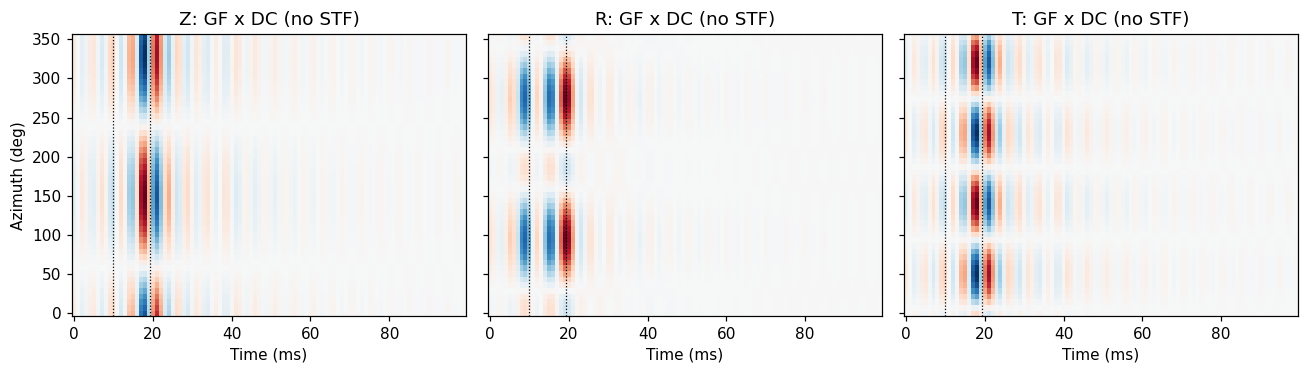

In [5]:
# Quick look at the formal GFs (Z, R, T), sorted by azimuth (expect P at ~9.9 ms and S at ~19.2 ms):
fig, axes = plt.subplots(1, 3, figsize=(12, 3.5), sharey=True)
t = ds_gf.times
for ax, c in zip(axes, 'ZRT'):
    sel = np.char.endswith(ds_gf.labels.astype(str), c)
    g = forward.synthetics(ds_gf.gf['mt'][sel], mt.from_sdr(30, 60, -60))
    vmax = np.abs(g).max()
    ax.pcolormesh(t * 1e3, rec_az, g, cmap='RdBu', vmin=-vmax, vmax=vmax)
    for tt in (radius / vp, radius / vs):
        ax.axvline(tt * 1e3, color='k', ls=':', lw=0.8)
    ax.set_title(f'{c}: GF x DC (no STF)')
    ax.set_xlabel('Time (ms)')
axes[0].set_ylabel('Azimuth (deg)')
fig.tight_layout()

## 3. Known source and synthetic data

- **Source:** an oblique double couple (strike 30°, dip 60°, rake −60°), so the ring has no complete P nodes.
- **Data:** the GFs × the MT, convolved with the "true" STF, plus Gaussian noise band-limited by B (peak SNR ≈ 50).
- **Two data sets:**
  - a single Brune with $f_c$ = 60 Hz;
  - a two-Brune source (symmetric + directional, shared $f_{c0}$).

In [6]:
rng = np.random.default_rng(0)
m_true = mt.from_sdr(30, 60, -60)
fc_true = 60.0
snr = 50.0

def add_noise(d, rng):
    n = forward.bandlimit(rng.standard_normal(d.shape), dt, band)
    return d + n * (np.abs(d).max() / snr) / n.std()

def brune_synth(gf, m, fc):
    # MT synthetics convolved with a causal Brune STF (fc scalar or (n_rec,)).
    fc = np.asarray(fc, dtype=float)
    return forward.convolve_stf(forward.synthetics(gf, m), dt,
                                lambda f: stfs.brune_stf_spectrum(f, fc[..., None]))

G = ds_gf.gf['mt']
d1_clean = brune_synth(G, m_true, fc_true)
d1 = add_noise(d1_clean, rng)
ds1 = unshake.Dataset(data=d1, gf=ds_gf.gf, dt=dt, receivers=ds_gf.receivers, source=ds_gf.source,
                      meta=dict(ds_gf.meta))

# Two-Brune source: symmetric STF with corner fc0, plus a directional STF whose corner is fc0
# perpendicular to the rupture and Doppler-shifted elsewhere (rupture to azimuth 45 deg, horizontal):
model2 = unshake.MTTwoBruneModel(scale=mt.norm(m_true))
p2_true = np.r_[m_true, 60.0, 0.6, 0.6 * vs, np.radians(45.0), 0.0]   # fc0, w2, vr, az, plunge
I_FC0, I_W2, I_VR, I_AZ, I_PL = 6, 7, 8, 9, 10                        # parameter indices
d2_clean = model2.forward(p2_true, ds_gf)[0]
d2 = add_noise(d2_clean, rng)
ds2 = unshake.Dataset(data=d2, gf=ds_gf.gf, dt=dt, receivers=ds_gf.receivers, source=ds_gf.source,
                      meta=dict(ds_gf.meta))

# Quick sanity checks on the new STF code:
f_chk = np.linspace(0, 500, 501)
assert np.allclose(np.abs(stfs.brune_stf_spectrum(f_chk, 60.0)), spectra.brune(f_chk, 60.0))
for k in (I_W2, I_VR):                                   # w2 = 0 or vr = 0 -> single Brune with corner fc0
    p_chk = p2_true.copy(); p_chk[k] = 0.0
    assert np.allclose(model2.forward(p_chk, ds_gf)[0], brune_synth(G, m_true, p2_true[I_FC0]))
print('checks OK')

def comp(ds, c):
    # Sub-Dataset of one component ('Z', 'R' or 'T'), in azimuth order.
    return ds.subset(np.flatnonzero(np.char.endswith(ds.labels.astype(str), c)))

def spec3(x):
    # Per-receiver 3-component amplitude spectrum: root-sum-square over Z, R, T of
    # x (..., 3 * n_rec, n_t) -> (f, (..., n_rec, n_f)). Avoids the radiation-pattern holes of single components.
    f, X = spectra.amplitude_spectrum(x, dt)
    X = X.reshape(X.shape[:-2] + (3, n_rec, X.shape[-1]))
    return f, np.sqrt(np.sum(X ** 2, axis=-3))

checks OK


## 4. Single Brune STF: effect of the corner frequency

### 4.1 The STFs themselves

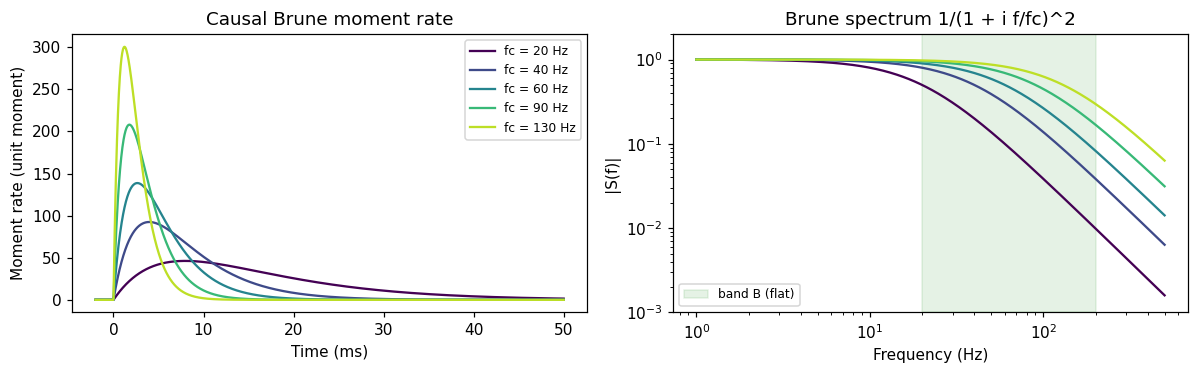

In [7]:
fcs = [20.0, 40.0, 60.0, 90.0, 130.0]
cols = plt.cm.viridis(np.linspace(0, 0.9, len(fcs)))
tt = np.linspace(-0.002, 0.05, 2000)
ff = np.logspace(0, np.log10(500), 400)
fig, axes = plt.subplots(1, 2, figsize=(11, 3.5))
for fc, col in zip(fcs, cols):
    axes[0].plot(tt * 1e3, stfs.brune_stf(tt, fc), color=col, label=f'fc = {fc:g} Hz')
    axes[1].loglog(ff, np.abs(stfs.brune_stf_spectrum(ff, fc)), color=col)
axes[0].set(xlabel='Time (ms)', ylabel='Moment rate (unit moment)', title='Causal Brune moment rate')
axes[0].legend(fontsize=8)
axes[1].axvspan(band[1], band[2], color='g', alpha=0.1, label='band B (flat)')
axes[1].set(xlabel='Frequency (Hz)', ylabel='|S(f)|', title='Brune spectrum 1/(1 + i f/fc)^2', ylim=(1e-3, 2))
axes[1].legend(fontsize=8)
fig.tight_layout()

### 4.2 Spectra: data vs. models with different fc
- Three-component amplitude spectra (root-sum-square over Z, R, T) at four azimuths, plus the median over receivers.
- The data are noisy, with true fc = 60 Hz. The noise-free data are dashed.
- Outside the shaded band B, the spectra are only the band filter.

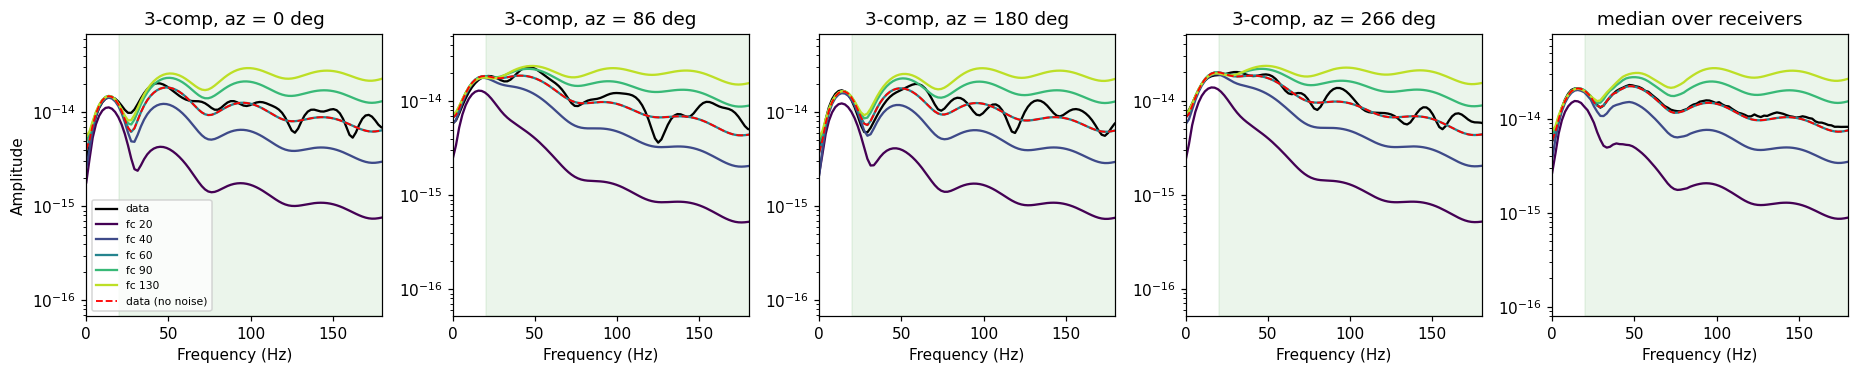

In [8]:
comp_plot = 'R'                                               # component for record sections below
synths = {fc: brune_synth(G, m_true, fc) for fc in fcs}
idx_show = [0, 12, 25, 37]                                     # azimuths 0, 86.4, 180, 266.4 deg
f, D = spec3(ds1.data)
_, Dc = spec3(d1_clean)
S = {fc: spec3(synths[fc])[1] for fc in fcs}
fig, axes = plt.subplots(1, 5, figsize=(17, 3.5), sharex=True)
for ax, i in zip(axes[:4], idx_show):
    ax.semilogy(f, D[i], 'k', lw=1.5, label='data')
    for fc, col in zip(fcs, cols):
        ax.semilogy(f, S[fc][i], color=col, label=f'fc {fc:g}')
    ax.semilogy(f, Dc[i], color='r', ls='--', lw=1.2, label='data (no noise)')
    ax.set_title(f'3-comp, az = {rec_az[i]:.0f} deg')
ax = axes[4]
ax.semilogy(f, np.median(D, 0), 'k', lw=1.5)
for fc, col in zip(fcs, cols):
    ax.semilogy(f, np.median(S[fc], 0), color=col)
ax.semilogy(f, np.median(Dc, 0), color='r', ls='--', lw=1.2)
ax.set_title('median over receivers')
for ax in axes:
    ax.axvspan(band[1], band[2], color='g', alpha=0.08)
    ax.set_xlim(0, 180)
    ax.set_xlabel('Frequency (Hz)')
    lim = ax.get_ylim()
    ax.set_ylim(lim[1] * 1e-3, lim[1])
axes[0].set_ylabel('Amplitude')
axes[0].legend(fontsize=7)
fig.tight_layout()

### 4.3 Waveforms
Record sections sorted by azimuth (R component, normalised per trace), for under-estimated, true and over-estimated fc. Below them, trace overlays for a few azimuths.

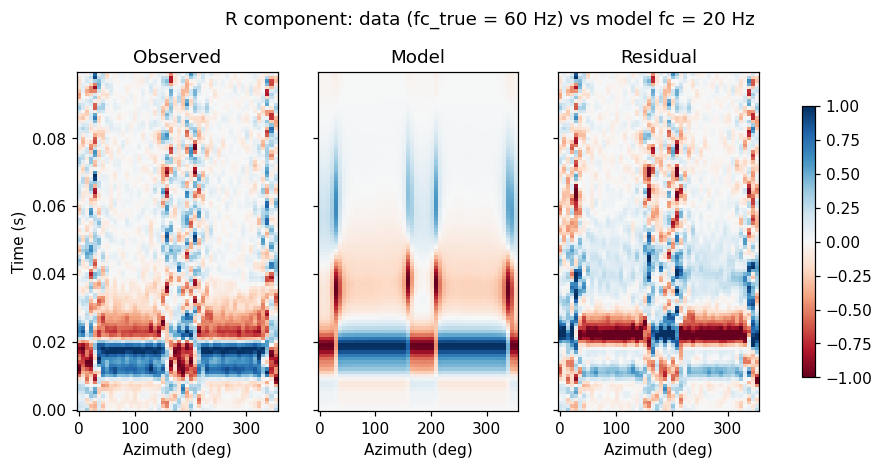

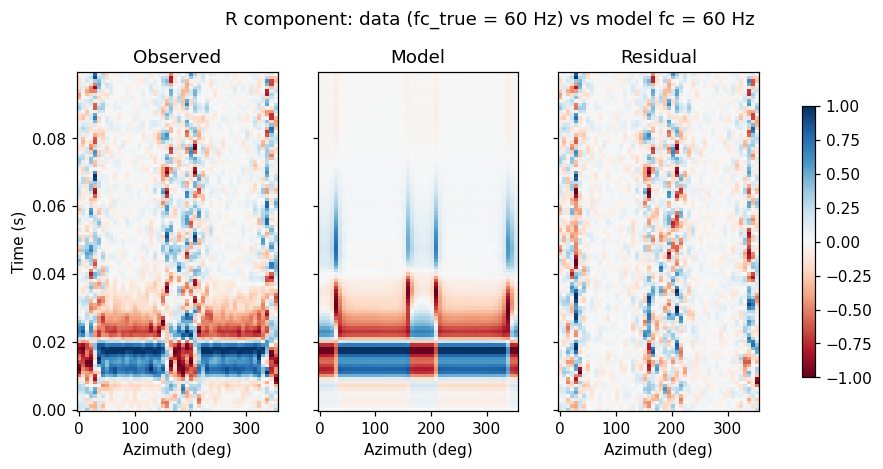

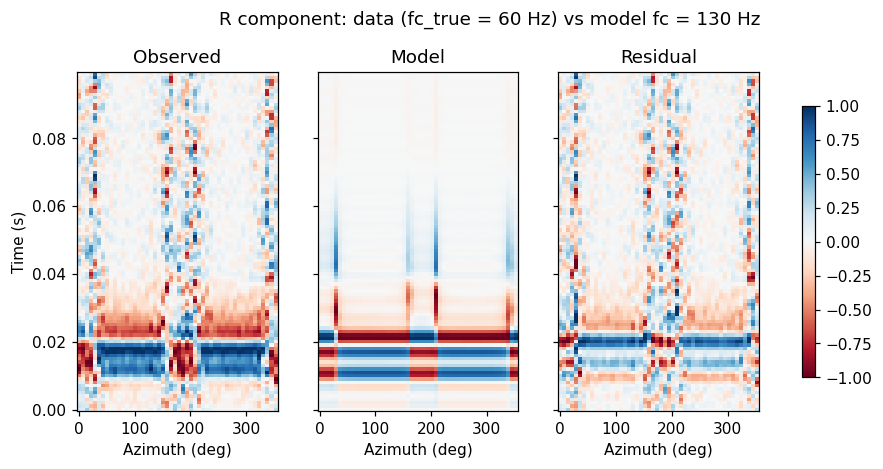

In [9]:
for fc in (20.0, 60.0, 130.0):
    fig = plot.wavefield(comp(ds1, comp_plot), comp(unshake.Dataset(data=synths[fc], gf=ds_gf.gf, dt=dt,
                         receivers=ds_gf.receivers), comp_plot).data, x=rec_az, xlabel='Azimuth (deg)')
    fig.suptitle(f'{comp_plot} component: data (fc_true = {fc_true:g} Hz) vs model fc = {fc:g} Hz', y=1.02)

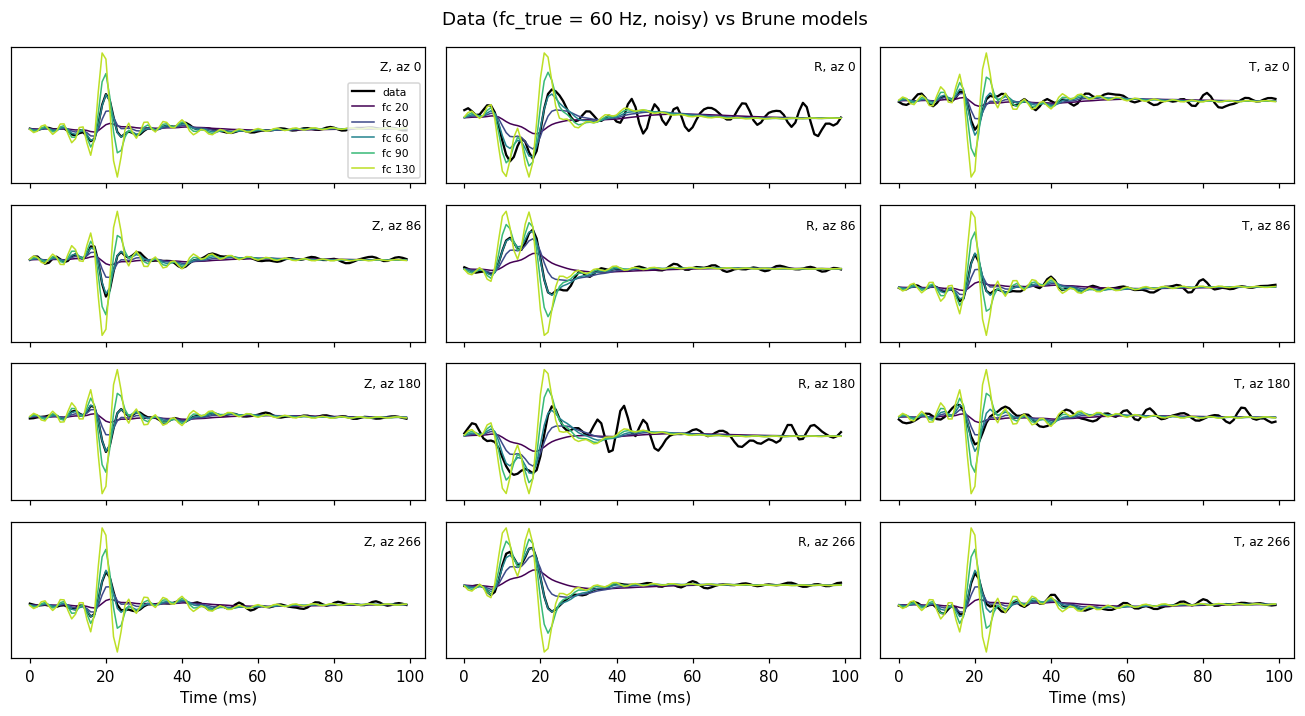

In [10]:
def trace_panel(ds, synth_dict, comps=('Z', 'R', 'T'), idx=(0, 12, 25, 37), colors=None, title=''):
    # Data (black) vs several models, for receivers idx (ring indices) and components (columns).
    fig, axes = plt.subplots(len(idx), len(comps), figsize=(4 * len(comps), 1.4 * len(idx) + 1),
                             sharex=True, squeeze=False)
    for col_j, c in enumerate(comps):
        sel = np.flatnonzero(np.char.endswith(ds.labels.astype(str), c))
        for row_i, i in enumerate(idx):
            ax = axes[row_i, col_j]
            ax.plot(ds.times * 1e3, ds.data[sel[i]], 'k', lw=1.5, label='data')
            for (lab, s), colr in zip(synth_dict.items(), colors if colors is not None else [None] * len(synth_dict)):
                ax.plot(ds.times * 1e3, s[sel[i]], lw=1, color=colr, label=lab)
            ax.text(0.99, 0.9, f'{c}, az {rec_az[i]:.0f}', transform=ax.transAxes, ha='right', va='top', fontsize=8)
            ax.set_yticks([])
    axes[0, 0].legend(fontsize=7, loc='lower right')
    for ax in axes[-1]:
        ax.set_xlabel('Time (ms)')
    fig.suptitle(title)
    fig.tight_layout()
    return fig

trace_panel(ds1, {f'fc {fc:g}': synths[fc] for fc in fcs}, colors=cols,
            title=f'Data (fc_true = {fc_true:g} Hz, noisy) vs Brune models');

### 4.4 Misfit against fc (a 1-D scan, not an inversion)
The MT and the amplitude are held at their true values. The VR is computed over all traces and components.

best fc: noisy 60.1 Hz (VR 0.963), noise-free 60.1 Hz (VR 1.000)


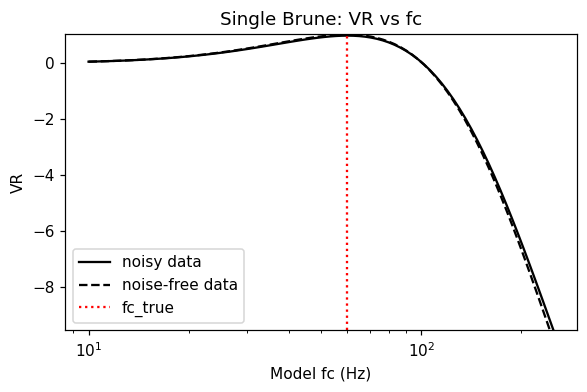

In [11]:
fc_scan = np.logspace(1, np.log10(250), 80)
synth_scan = brune_synth(G, m_true, fc_scan[:, None])          # (n_fc, n_traces, n_t)
vr1 = misfit.vr(ds1.data, synth_scan)
vr1_clean = misfit.vr(d1_clean, synth_scan)
fig, ax = plt.subplots(figsize=(6, 3.5))
ax.semilogx(fc_scan, vr1, 'k', label='noisy data')
ax.semilogx(fc_scan, vr1_clean, 'k--', label='noise-free data')
ax.axvline(fc_true, color='r', ls=':', label='fc_true')
ax.set(xlabel='Model fc (Hz)', ylabel='VR', title='Single Brune: VR vs fc', ylim=(min(0, vr1.min()), 1.02))
ax.legend()
print(f"best fc: noisy {fc_scan[np.argmax(vr1)]:.1f} Hz (VR {vr1.max():.3f}), "
      f"noise-free {fc_scan[np.argmax(vr1_clean)]:.1f} Hz (VR {vr1_clean.max():.3f})")

### 4.5 Interactive: vary fc

In [12]:
import ipywidgets as widgets

def show_fc(fc=60.0, receiver=0, component='R'):
    s = brune_synth(G, m_true, fc)
    sel = np.flatnonzero(np.char.endswith(ds1.labels.astype(str), component))[receiver]
    fig, axes = plt.subplots(1, 3, figsize=(15, 3.5))
    f, D = spectra.amplitude_spectrum(ds1.data[sel], dt)
    axes[0].semilogy(f, D, 'k', label='data')
    axes[0].semilogy(f, spectra.amplitude_spectrum(s[sel], dt)[1], 'r', label=f'model fc {fc:.0f}')
    axes[0].set(xlim=(0, 180), xlabel='Frequency (Hz)', title=f'{component}, az {rec_az[receiver]:.0f} deg')
    axes[0].set_ylim(D.max() * 1e-3, D.max() * 3)
    axes[0].axvspan(band[1], band[2], color='g', alpha=0.08)
    axes[0].legend()
    axes[1].plot(ds1.times * 1e3, ds1.data[sel], 'k')
    axes[1].plot(ds1.times * 1e3, s[sel], 'r')
    axes[1].set(xlabel='Time (ms)', title=f'VR (all traces) = {misfit.vr(ds1.data, s):.3f}')
    tt = np.linspace(-0.002, 0.05, 1000)
    axes[2].plot(tt * 1e3, stfs.brune_stf(tt, fc_true), 'k', label='true STF')
    axes[2].plot(tt * 1e3, stfs.brune_stf(tt, fc), 'r', label='model STF')
    axes[2].set(xlabel='Time (ms)', title='Moment rate')
    axes[2].legend()
    fig.tight_layout()
    plt.show()

widgets.interact(show_fc,
                 fc=widgets.FloatLogSlider(value=60.0, base=10, min=1, max=np.log10(300), step=0.02),
                 receiver=widgets.IntSlider(value=0, min=0, max=n_rec - 1),
                 component=['Z', 'R', 'T']);

interactive(children=(FloatLogSlider(value=60.0, description='fc', max=2.4771212547196626, min=1.0, step=0.02)…

## 5. Two Brune STFs: one symmetric, one directional, sharing one corner frequency

$$S_i(f) = (1-w_2)\,S(f; f_{c0}) + w_2\,S\big(f; f_{c2}(\hat r_i)\big), \qquad f_{c2}(\hat r_i) = \frac{f_{c0}}{1 - (v_r/c)\cos\theta_i}$$

The directional STF's corner frequency perpendicular to the rupture is constrained to equal the symmetric STF's corner, $f_{c0}$.

True source parameters:
- shared corner frequency $f_{c0}$ = 60 Hz;
- directional moment fraction $w_2$ = 0.6 (the same at every receiver), so $1 - w_2$ = 0.4 is symmetric;
- rupture: unilateral at $v_r = 0.6\,v_s$ towards azimuth 45°, horizontal.

Doppler uses one phase velocity per trace, $c = v_p$. The window contains both P and S, so this is a demo simplification. A later refinement would use separate P and S windows, each with its own $c$.

### 5.1 Apparent fc2 against azimuth, and the effective STF

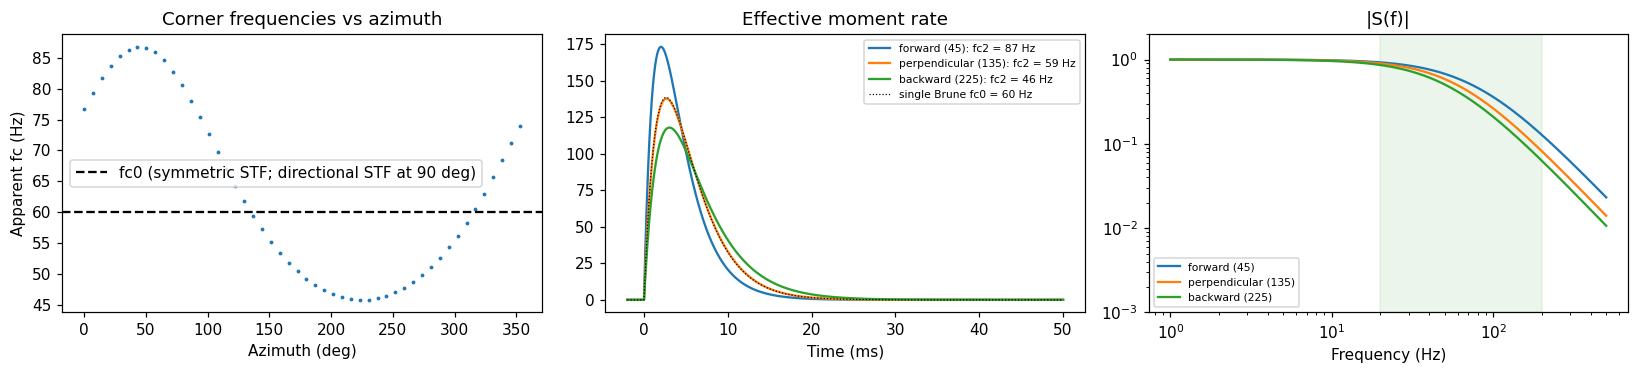

In [13]:
ds_R = comp(ds_gf, 'R')
fig, axes = plt.subplots(1, 3, figsize=(15, 3.5))
plot.fc_azimuth(model2, p2_true, ds_R, ax=axes[0])
axes[0].axhline(p2_true[I_FC0], color='k', ls='--', label='fc0 (symmetric STF; directional STF at 90 deg)')
axes[0].legend()
axes[0].set_title('Corner frequencies vs azimuth')
fc2_R = model2.corner_frequencies(p2_true, ds_R)[0]
tt = np.linspace(-0.002, 0.05, 2000)
ff = np.logspace(0, np.log10(500), 400)
fc0, w2 = p2_true[I_FC0], p2_true[I_W2]
for name, az0 in (('forward (45)', 45.0), ('perpendicular (135)', 135.0), ('backward (225)', 225.0)):
    i = int(np.argmin(np.abs(rec_az - az0)))
    stf_t = (1 - w2) * stfs.brune_stf(tt, fc0) + w2 * stfs.brune_stf(tt, fc2_R[i])
    axes[1].plot(tt * 1e3, stf_t, label=f'{name}: fc2 = {fc2_R[i]:.0f} Hz')
    axes[2].loglog(ff, np.abs(stfs.two_brune_spectrum(ff, fc0, fc2_R[i], w2)), label=name)
axes[1].plot(tt * 1e3, stfs.brune_stf(tt, fc0), 'k:', lw=0.8, label=f'single Brune fc0 = {fc0:g} Hz')
axes[1].set(xlabel='Time (ms)', title='Effective moment rate')
axes[1].legend(fontsize=7)
axes[2].axvspan(band[1], band[2], color='g', alpha=0.08)
axes[2].set(xlabel='Frequency (Hz)', title='|S(f)|', ylim=(1e-3, 2))
axes[2].legend(fontsize=7)
fig.tight_layout()

### 5.2 Best single Brune vs the true two-Brune model
First, find the single Brune fc that fits the two-Brune data best, with the same 1-D VR scan. Its misfit pattern across azimuth then shows the directional signature.

best single Brune fc = 62.6 Hz: VR 0.906;  true two-Brune model: VR 0.940


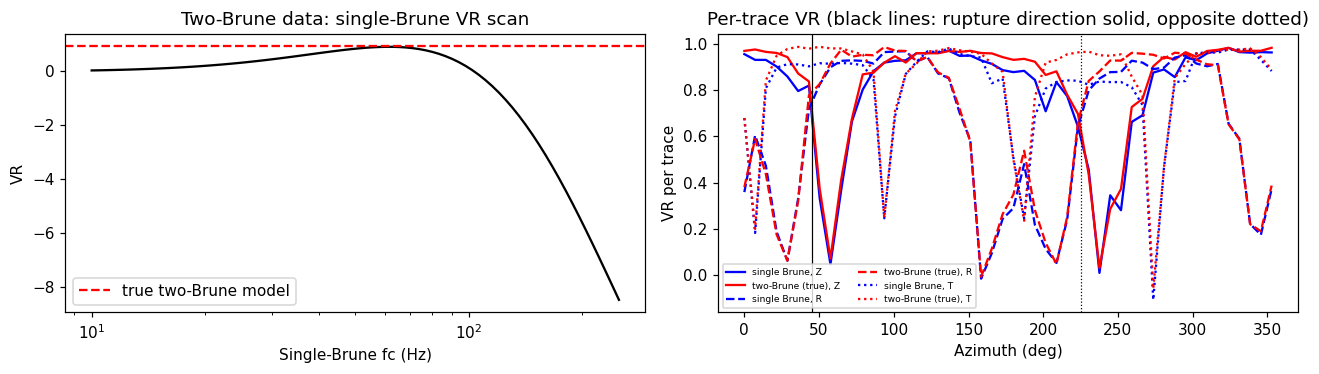

In [14]:
vr2 = misfit.vr(ds2.data, synth_scan)
fc_best2 = fc_scan[np.argmax(vr2)]
s2_single = brune_synth(G, m_true, fc_best2)
s2_true = model2.forward(p2_true, ds_gf)[0]
print(f"best single Brune fc = {fc_best2:.1f} Hz: VR {vr2.max():.3f};  true two-Brune model: VR {misfit.vr(ds2.data, s2_true):.3f}")

fig, axes = plt.subplots(1, 2, figsize=(12, 3.5))
axes[0].semilogx(fc_scan, vr2, 'k')
axes[0].axhline(misfit.vr(ds2.data, s2_true), color='r', ls='--', label='true two-Brune model')
axes[0].set(xlabel='Single-Brune fc (Hz)', ylabel='VR', title='Two-Brune data: single-Brune VR scan')
axes[0].legend()
# Per-receiver VR vs azimuth:
def vr_per_trace(d, s):
    return 1.0 - np.sum((d - s) ** 2, -1) / np.sum(d ** 2, -1)
for c, ls in zip('ZRT', ('-', '--', ':')):
    sel = np.char.endswith(ds2.labels.astype(str), c)
    axes[1].plot(rec_az, vr_per_trace(ds2.data[sel], s2_single[sel]), 'b', ls=ls, label=f'single Brune, {c}')
    axes[1].plot(rec_az, vr_per_trace(ds2.data[sel], s2_true[sel]), 'r', ls=ls, label=f'two-Brune (true), {c}')
axes[1].axvline(45, color='k', lw=0.8)
axes[1].axvline(225, color='k', lw=0.8, ls=':')
axes[1].set(xlabel='Azimuth (deg)', ylabel='VR per trace', title='Per-trace VR (black lines: rupture direction solid, opposite dotted)')
axes[1].legend(fontsize=6, ncol=2)
fig.tight_layout()

### 5.3 Spectral ratio by azimuth
The plot shows the data spectrum divided by the best single-Brune model spectrum, per receiver, sorted by azimuth. Both spectra are 3-component (root-sum-square over Z, R, T), which avoids nodal holes. The ratio is 1 if the source is a single, non-directional Brune. Above about 60 Hz the ratio is high towards the rupture direction (45°) and low away from it (225°).

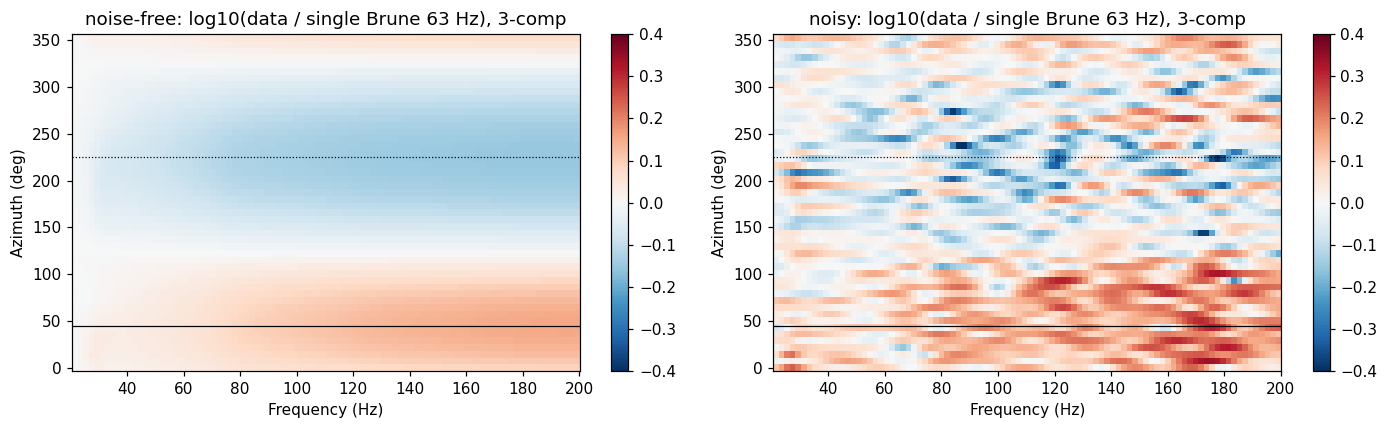

In [15]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
for ax, (lab, d) in zip(axes, (('noise-free', d2_clean), ('noisy', ds2.data))):
    f, D = spec3(d)
    _, S = spec3(s2_single)
    keep = (f >= band[1]) & (f <= band[2])
    im = ax.pcolormesh(f[keep], rec_az, np.log10(D[:, keep] / S[:, keep]), cmap='RdBu_r', vmin=-0.4, vmax=0.4,
                       shading='nearest')
    ax.axhline(45, color='k', lw=0.8)
    ax.axhline(225, color='k', lw=0.8, ls=':')
    ax.set(xlabel='Frequency (Hz)', ylabel='Azimuth (deg)',
           title=f'{lab}: log10(data / single Brune {fc_best2:.0f} Hz), 3-comp')
    fig.colorbar(im, ax=ax)
fig.tight_layout()

### 5.4 Waveforms

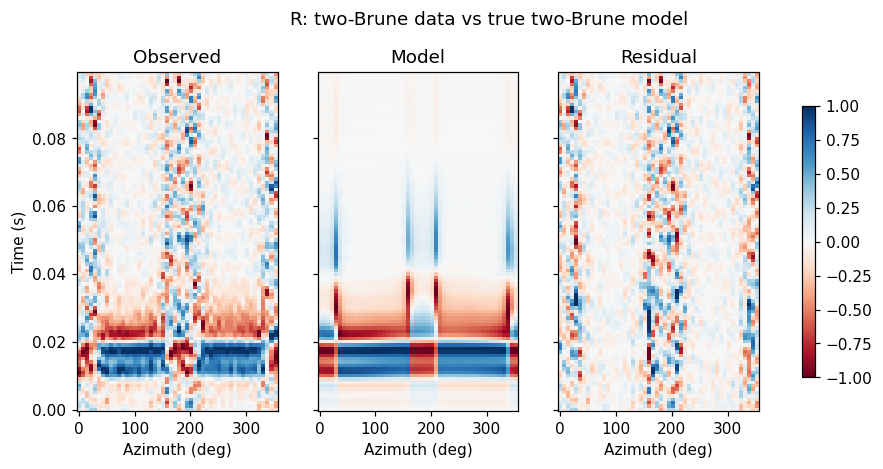

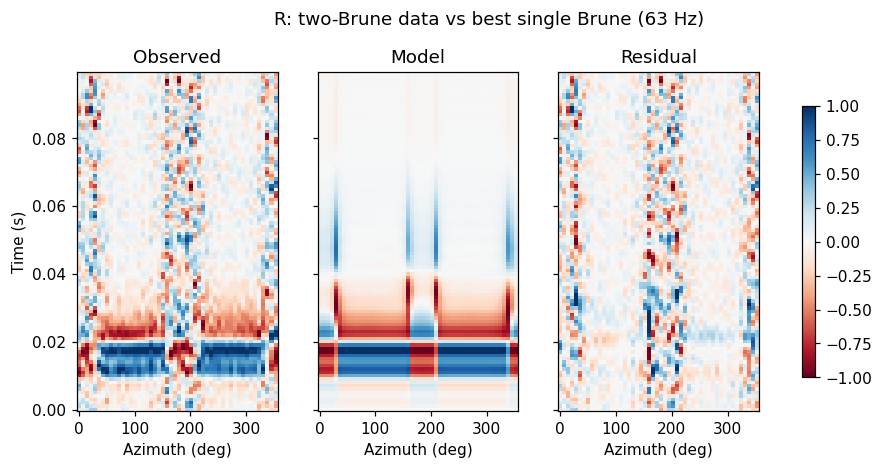

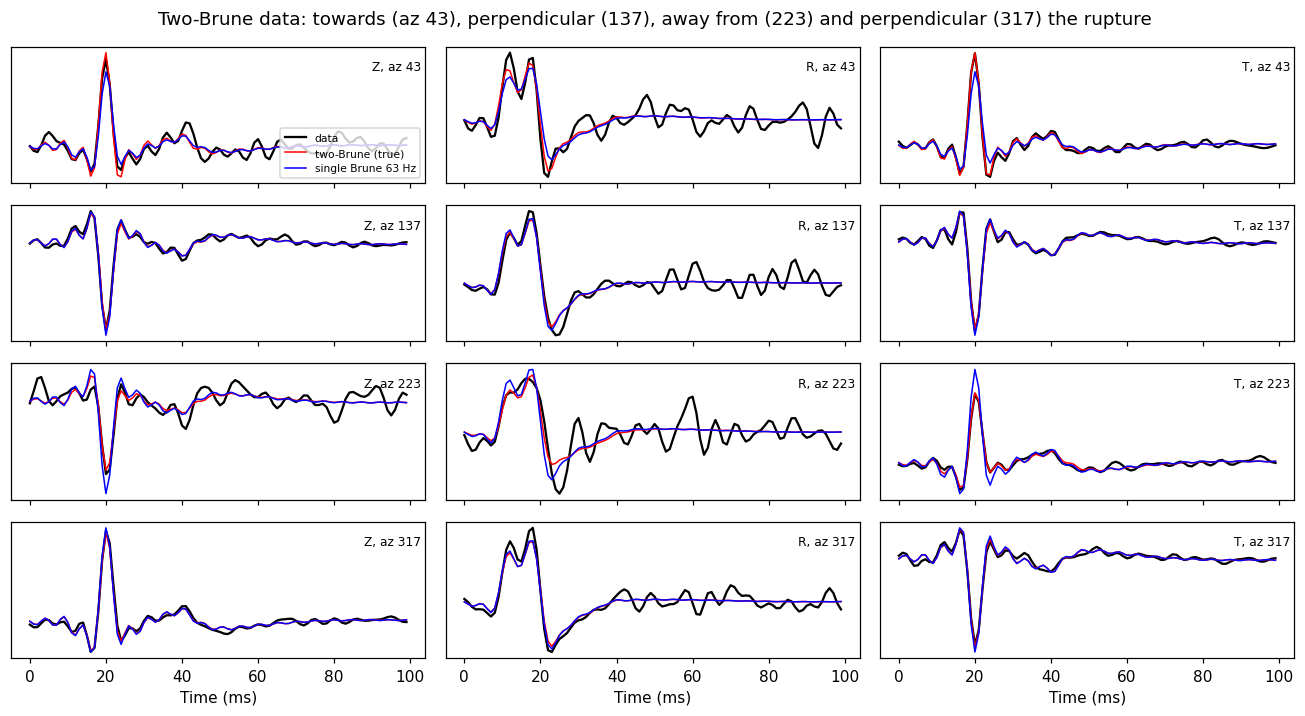

In [16]:
fig = plot.wavefield(comp(ds2, 'R'), comp(unshake.Dataset(data=s2_true, gf=ds_gf.gf, dt=dt, receivers=ds_gf.receivers), 'R').data,
                     x=rec_az, xlabel='Azimuth (deg)')
fig.suptitle('R: two-Brune data vs true two-Brune model', y=1.02)
fig = plot.wavefield(comp(ds2, 'R'), comp(unshake.Dataset(data=s2_single, gf=ds_gf.gf, dt=dt, receivers=ds_gf.receivers), 'R').data,
                     x=rec_az, xlabel='Azimuth (deg)')
fig.suptitle(f'R: two-Brune data vs best single Brune ({fc_best2:.0f} Hz)', y=1.02)
trace_panel(ds2, {'two-Brune (true)': s2_true, f'single Brune {fc_best2:.0f} Hz': s2_single},
            idx=(6, 19, 31, 44), colors=['r', 'b'],
            title='Two-Brune data: towards (az 43), perpendicular (137), away from (223) and perpendicular (317) the rupture');

### 5.5 Interactive: vary the two-Brune parameters

In [ ]:
def show_two(fc0=60.0, w2=0.6, vr_over_vs=0.6, rupt_az=45.0, component='R'):
    p = np.r_[m_true, fc0, w2, vr_over_vs * vs, np.radians(rupt_az), 0.0]
    s = model2.forward(p, ds_gf)[0]
    # True (data) vs model parameters:
    print(f"{'':>14}{'true (data)':>13}{'model':>9}")
    for name, tv, mv in (('fc0 (Hz)', p2_true[I_FC0], fc0),
                         ('w2', p2_true[I_W2], w2), ('1 - w2', 1 - p2_true[I_W2], 1 - w2),
                         ('vr / vs', p2_true[I_VR] / vs, vr_over_vs),
                         ('w2 * vr / c', p2_true[I_W2] * p2_true[I_VR] / vp, w2 * vr_over_vs * vs / vp),
                         ('rupt_az (deg)', np.degrees(p2_true[I_AZ]), rupt_az),
                         ('rupt_plunge', np.degrees(p2_true[I_PL]), 0.0)):
        print(f"{name:>14}{tv:>13.3g}{mv:>9.3g}")
    print(f"{'c (m/s)':>14}{vp:>13.0f}{vp:>9.0f}   (phase velocity for Doppler)")
    sel = np.flatnonzero(np.char.endswith(ds2.labels.astype(str), component))
    fig, axes = plt.subplots(1, 3, figsize=(16, 3.8))
    axes[0].plot(rec_az, model2.corner_frequencies(p2_true, comp(ds_gf, component))[0], 'k', label='fc2 (true)')
    axes[0].plot(rec_az, model2.corner_frequencies(p, comp(ds_gf, component))[0], 'r', label='fc2 (model)')
    axes[0].axhline(p2_true[I_FC0], color='k', ls='--', label='fc0 (true)')
    axes[0].axhline(fc0, color='r', ls='--', label='fc0 (model)')
    axes[0].set(xlabel='Azimuth (deg)', ylabel='fc (Hz)', title='Corner frequencies')
    axes[0].legend(fontsize=7)
    f, D = spec3(ds2.data)
    _, S = spec3(s)
    keep = (f >= band[1]) & (f <= band[2])
    im = axes[1].pcolormesh(f[keep], rec_az, np.log10(D[:, keep] / S[:, keep]), cmap='RdBu_r', vmin=-0.4, vmax=0.4,
                            shading='nearest')
    fig.colorbar(im, ax=axes[1])
    axes[1].set(xlabel='Frequency (Hz)', ylabel='Azimuth (deg)', title='log10(data / model), 3-comp')
    i = int(np.argmin(np.abs(rec_az - rupt_az)))
    axes[2].plot(ds2.times * 1e3, ds2.data[sel[i]], 'k', label='data')
    axes[2].plot(ds2.times * 1e3, s[sel[i]], 'r', label='model')
    axes[2].set(xlabel='Time (ms)', title=f'az {rec_az[i]:.0f} deg; VR (all) = {misfit.vr(ds2.data, s):.3f}')
    axes[2].legend(fontsize=7)
    fig.tight_layout()
    plt.show()

widgets.interact(show_two,
                 fc0=widgets.FloatLogSlider(value=60.0, base=10, min=1, max=np.log10(300), step=0.02),
                 w2=widgets.FloatSlider(value=0.6, min=0.0, max=1.0, step=0.05),
                 vr_over_vs=widgets.FloatSlider(value=0.6, min=0.0, max=0.95, step=0.05),
                 rupt_az=widgets.FloatSlider(value=45.0, min=0.0, max=360.0, step=5.0),
                 component=['Z', 'R', 'T']);

interactive(children=(FloatLogSlider(value=60.0, description='fc0', max=2.4771212547196626, min=1.0, step=0.02…

### 5.6 Trade-off between $w_2$ and $v_r$ (a 2-D misfit scan, not an inversion)
With a shared $f_{c0}$, the directional STF differs from the symmetric one only through the Doppler shift. For small $v_r/c$, $f_{c2} \approx f_{c0}\,(1 + (v_r/c)\cos\theta)$, so

$$S_i(f) \approx S(f; f_{c0}) + w_2\,\frac{v_r}{c}\,\cos\theta_i\; f_{c0}\,\frac{\partial S}{\partial f_{c0}},$$

and only the product $w_2\, v_r / c$ is constrained to first order. Higher-order terms (the forward/backward asymmetry of $1/(1 - x)$) separate $w_2$ and $v_r$, but only weakly. Below, $f_{c0}$ and the rupture direction are held at their true values; the dashed line is the curve of constant $w_2\, v_r$ through the true value.

noise-free: best w2 = 0.60, vr/vs = 0.61 (VR 1.0000); true VR 1.0000; w2 = 1, vr/vs = 0.36 (same product) VR 0.9991
noisy: best w2 = 0.64, vr/vs = 0.57 (VR 0.9405); true VR 0.9405; w2 = 1, vr/vs = 0.36 (same product) VR 0.9398


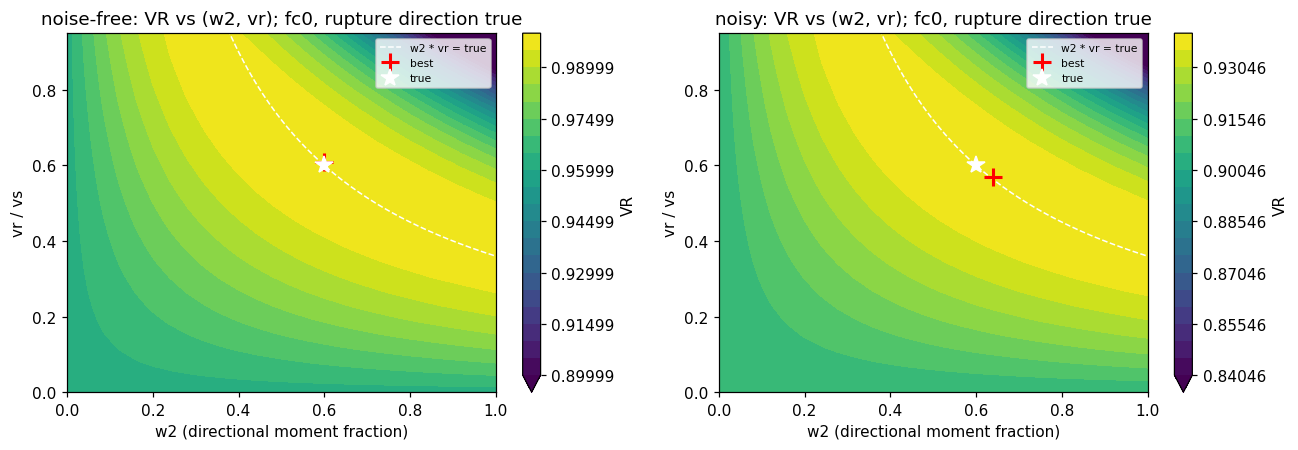

In [18]:
w2_grid = np.linspace(0.0, 1.0, 26)
vr_grid = np.linspace(0.0, 0.95, 26) * vs
W2, VR = np.meshgrid(w2_grid, vr_grid, indexing='ij')
p_grid = np.tile(p2_true, (W2.size, 1))
p_grid[:, I_W2], p_grid[:, I_VR] = W2.ravel(), VR.ravel()
s_grid = np.concatenate([model2.forward(pp, ds_gf) for pp in np.array_split(p_grid, 10)])
prod = p2_true[I_W2] * p2_true[I_VR]
fig, axes = plt.subplots(1, 2, figsize=(12, 4.2))
for ax, (lab, d) in zip(axes, (('noise-free', d2_clean), ('noisy', ds2.data))):
    v = misfit.vr(d, s_grid).reshape(W2.shape)
    im = ax.contourf(W2, VR / vs, v, levels=np.linspace(v.max() - 0.1, v.max(), 21), extend='min', cmap='viridis')
    fig.colorbar(im, ax=ax, label='VR')
    w = np.linspace(0.05, 1.0, 200)
    ax.plot(w, prod / w / vs, 'w--', lw=1, label='w2 * vr = true')
    i_best = np.unravel_index(np.argmax(v), v.shape)
    ax.plot(W2[i_best], VR[i_best] / vs, 'r+', ms=12, mew=2, label='best')
    ax.plot(p2_true[I_W2], p2_true[I_VR] / vs, 'w*', ms=12, label='true')
    ax.set(xlim=(0, 1), ylim=(0, 0.95), xlabel='w2 (directional moment fraction)', ylabel='vr / vs',
           title=f'{lab}: VR vs (w2, vr); fc0, rupture direction true')
    ax.legend(fontsize=7, loc='upper right')
    p_alt = p2_true.copy(); p_alt[I_W2], p_alt[I_VR] = 1.0, prod        # pure directional, same w2 * vr
    print(f"{lab}: best w2 = {W2[i_best]:.2f}, vr/vs = {VR[i_best] / vs:.2f} (VR {v.max():.4f}); "
          f"true VR {misfit.vr(d, model2.forward(p2_true, ds_gf)[0]):.4f}; "
          f"w2 = 1, vr/vs = {prod / vs:.2f} (same product) VR {misfit.vr(d, model2.forward(p_alt, ds_gf)[0]):.4f}")
fig.tight_layout()